# Triangular FX arbitrage: quote freshness and apparent opportunities

**Final exploratory analysis · EUR/USD, USD/JPY and EUR/JPY · October 2025**

## Summary

This study compares positive quoted triangular returns over two trading weeks and tests whether they persist when all three quotes must be recent.

- **The weeks differ massively.** In 6–10 October, the reverse direction was positive in **12.44%** of event observations, versus **0.29%** forward. In 13–17 October, both directions were positive in approximately **0.28%** of observations.
- **The tested freshness filters do not resolve the first week's asymmetry.** Its reverse positive share remains **12.80%** with a 10 ms limit.
- **Coverage matters.** The 10 ms filter retains only about **1.1%** of either week's event observations. Filtered shares describe selected subsets, not the full weeks.

The result is a descriptive finding about recorded quotes, **not evidence of executable profit**. The original asymmetry remains unexplained.

## 1. Question and scope

**How frequent are positive triangular returns in these recorded quotes, and how sensitive are the results to quote freshness?**

The analysis uses two fixed periods: **6–10 October 2025** and **13–17 October 2025**, in UTC. The second, consecutive week was chosen after the first week's asymmetric results; it is a comparison sample, not a randomized or independently designed validation study.

Scope is limited to the two directions, the two weeks, and four freshness conditions. No trading strategy is fitted or optimized. Daily concentration is not assessed in this final report, so no claim is made about which day drives the first week's result.

## 2. Data and alignment

Tick quotes were obtained using the project's Dukascopy download function and stored as six local Parquet files in `data/raw/`. Each file contains bid and ask prices and volumes for one pair and week. Volumes are not used in the return calculation.

The pipeline takes the union of the three timestamp indices and carries forward the latest available quote for each pair. Analysis begins when all three pairs have started reporting. Each row represents an event snapshot, not a fixed interval of elapsed time. Quotes can be carried across gaps in the unfiltered case.

The original update timestamp is retained for each pair. Quote age is:

$$\text{quote age}=\text{event time}-\text{latest quote-update time}.$$

An unchanged price can still be part of a fresh update. The filters therefore use **quote-update age**, not time since the last price change.

### Reproducibility

This notebook runs independently of the other notebooks, using local raw data and functions in `src/fx_arbitrage/`. No downloads are performed. Run all cells from the repository root or the `notebooks/` directory. Required packages are Python 3.12, pandas, NumPy, Matplotlib, a pandas Parquet engine (such as PyArrow), and IPython/Jupyter for notebook display.

Charts and a machine-readable comparison are exported to `reports/`. Code cells are collapsed where the viewer supports that setting; saved outputs are included for reading without execution.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from fx_arbitrage.alignment import align_quotes, calculate_quote_ages
from fx_arbitrage.arbitrage import calculate_triangle_returns
from fx_arbitrage.analysis import fresh_quote_mask

OUTPUT = ROOT / "reports"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
weeks = {
    "6–10 Oct 2025": "2025-10-06_2025-10-10",
    "13–17 Oct 2025": "2025-10-13_2025-10-17",
}
directions = {
    "pair1_pair2_cross_return": "Forward",
    "cross_pair2_pair1_return": "Reverse",
}
thresholds = {"Unfiltered": None, "1,000 ms": 1000, "100 ms": 100, "10 ms": 10}

from IPython.display import display, HTML
import platform
import numpy as np
import matplotlib
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")


Python 3.12.14 | pandas 3.0.5 | NumPy 2.5.2 | Matplotlib 3.11.2


## 3. Return calculations

Each direction starts and ends with EUR. Selling the base currency uses the bid; buying it uses the ask.

**Forward: EUR → USD → JPY → EUR**

$$R_{forward}=\frac{bid_{EUR/USD}\,bid_{USD/JPY}}{ask_{EUR/JPY}}-1.$$

**Reverse: EUR → JPY → USD → EUR**

$$R_{reverse}=\frac{bid_{EUR/JPY}}{ask_{EUR/USD}\,ask_{USD/JPY}}-1.$$

Positive means strictly greater than zero, without an additional cost or minimum-profit hurdle. Bid–ask spreads are included through the formulas. Commissions, latency, slippage and capacity constraints are excluded. Returns are expressed in basis points where noted: **1 bp = 0.01%**, so decimal returns are multiplied by 10,000.

## 4. Freshness conditions and measures

Compare **unfiltered**, **1,000 ms**, **100 ms** and **10 ms** maximum ages. A filtered row is eligible only when every pair has a nonmissing, nonnegative quote age at or below the limit.

- **Positive share:** positive return observations divided by nonmissing retained return observations, separately for each direction.
- **Retained share:** eligible event rows divided by original aligned event rows; identical for both directions.
- **Positive episode:** a consecutive run of positive rows. Excluded or missing rows break a run. This is an observational grouping, not a count of independent executable trades.
- **Positive-return magnitude:** median and maximum among positive observations, in basis points.

Stale rows are replaced with missing values rather than removed before episode counting. A condition with no valid returns has an undefined positive share, not a zero share.


In [2]:
records = []
for week, dates in weeks.items():
    sources = [
        (pair, pd.read_parquet(ROOT / "data" / "raw" / f"{filename}_{dates}.parquet"))
        for pair, filename in [("EUR_USD", "EURUSD"), ("USD_JPY", "USDJPY"), ("EUR_JPY", "EURJPY")]
    ]
    aligned = align_quotes(*sources)
    returns = calculate_triangle_returns(aligned, "EUR_USD", "USD_JPY", "EUR_JPY")
    ages = calculate_quote_ages(aligned)
    for label, limit in thresholds.items():
        fresh = (pd.Series(True, index=returns.index) if limit is None
                 else fresh_quote_mask(ages, limit))
        for column, direction in directions.items():
            # Keep excluded rows as missing so they break positive episodes.
            values = returns[column].where(fresh)
            positive = values.gt(0)
            n_valid = int(values.count())
            records.append({
                "week": week, "threshold": label, "direction": direction,
                "n_original": len(returns), "n_retained": int(fresh.sum()),
                "n_valid_returns": n_valid, "n_positive": int(positive.sum()),
                "retained_share": float(fresh.mean()),
                "positive_share": float(positive.sum() / n_valid) if n_valid else float("nan"),
                "positive_episodes": int((positive & ~positive.shift(fill_value=False)).sum()),
                "median_positive_bps": values[positive].median() * 10000,
                "max_positive_bps": values[positive].max() * 10000,
            })
    del aligned, returns, ages, sources

comparison = pd.DataFrame(records)
comparison.to_csv(OUTPUT / "staleness_comparison.csv", index=False)


## 5. Positive-share results

The table reports percentages of valid observations within each condition. Both weeks use exactly the same pipeline and thresholds.


In [3]:
positive_table = comparison.pivot(index=["week", "threshold"], columns="direction", values="positive_share")
order = pd.MultiIndex.from_product([list(weeks), list(thresholds)], names=["week", "threshold"])
positive_table = positive_table.reindex(order)[["Forward", "Reverse"]] * 100
positive_table.columns = ["Forward positive (%)", "Reverse positive (%)"]
display(HTML(positive_table.to_html(float_format=lambda value: f"{value:.3f}")))


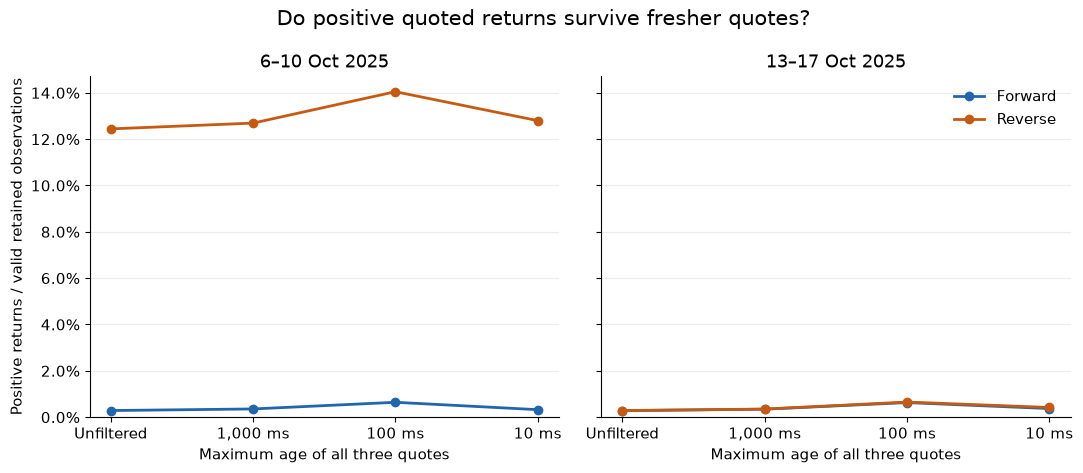

In [4]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
labels = list(thresholds)
colors = {"Forward": "#2166ac", "Reverse": "#c65a12"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, week in zip(axes, weeks):
    for direction in directions.values():
        rows = comparison[(comparison.week == week) & (comparison.direction == direction)].set_index("threshold").reindex(labels)
        ax.plot(labels, rows.positive_share * 100, marker="o", linewidth=2,
                label=direction, color=colors[direction])
    ax.set_title(week)
    ax.set_xlabel("Maximum age of all three quotes")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis="y", alpha=0.25)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Positive returns / valid retained observations")
axes[1].legend(frameon=False)
fig.suptitle("Do positive quoted returns survive fresher quotes?", fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES / "positive_share_by_staleness.png", dpi=180, bbox_inches="tight")
fig.savefig(FIGURES / "positive_share_by_staleness.svg", bbox_inches="tight")
plt.show()


The shared vertical scale makes the difference between weeks visible. The new week's directions almost overlap, while the original week's reverse direction is much higher throughout.

Positive share does **not** decline monotonically as the filter tightens. Both weeks and directions peak at the tested 100 ms condition, then decline at 10 ms. All 10 ms shares remain above their unfiltered values. These comparisons do not identify a causal effect of quote age: stricter eligibility selects different event observations and market conditions.

For example, the original reverse share rises from **12.443%** to **14.047%** at 100 ms, yet its positive observation count falls from **205,163** to **51,943**. A higher conditional share is not a larger total number of positive observations.

## 6. How much data remains?


In [5]:
coverage = comparison[comparison.direction.eq("Forward")][["week", "threshold", "n_original", "n_retained", "retained_share"]].copy()
coverage["retained_share"] *= 100
coverage = coverage.set_index(["week", "threshold"]).reindex(order)
coverage.columns = ["Original events", "Retained events", "Retained (%)"]
display(HTML(coverage.to_html(formatters={"Original events": "{:,.0f}".format, "Retained events": "{:,.0f}".format, "Retained (%)": "{:.2f}".format})))


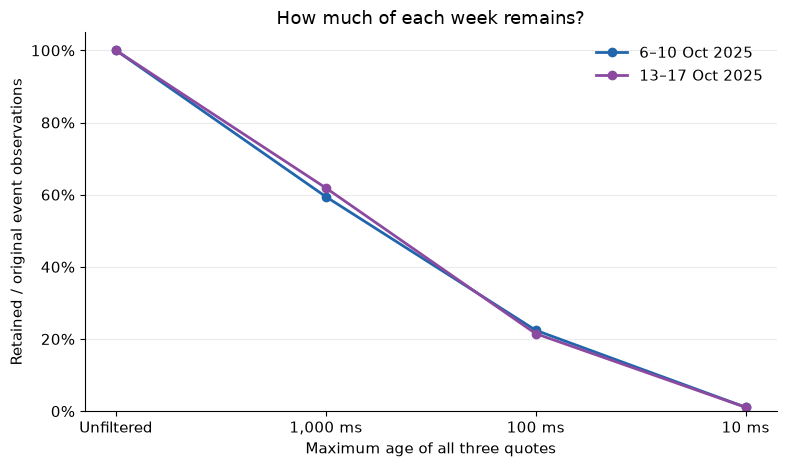

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for week, color in zip(weeks, ["#2166ac", "#8b4a9f"]):
    rows = comparison[(comparison.week == week) & (comparison.direction == "Forward")].set_index("threshold").reindex(labels)
    ax.plot(labels, rows.retained_share * 100, marker="o", linewidth=2, label=week, color=color)
ax.set(title="How much of each week remains?", xlabel="Maximum age of all three quotes",
       ylabel="Retained / original event observations", ylim=(0, 105))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "retained_share_by_staleness.png", dpi=180, bbox_inches="tight")
fig.savefig(FIGURES / "retained_share_by_staleness.svg", bbox_inches="tight")
plt.show()


At 1,000 ms, approximately **59–62%** of events remain. At 100 ms, coverage falls to **21–22%**. At 10 ms, only **18,218** observations in the original week and **19,359** in the second week remain—about **1.1%** each.

The strictest results therefore describe a small subset of events. Fresh quotes also do not guarantee simultaneous executability or persistence long enough to complete three conversions.

## 7. Magnitudes and observed episodes

Counts and magnitudes complement the share plots. These summaries are based on the same retained samples; return magnitudes below apply only to positive observations.


In [7]:
detail = comparison[["week", "threshold", "direction", "n_positive", "positive_episodes", "median_positive_bps", "max_positive_bps"]].copy()
detail = detail.set_index(["week", "threshold", "direction"])
detail.columns = ["Positive rows", "Positive episodes", "Median positive (bp)", "Maximum positive (bp)"]
display(HTML(detail.to_html(formatters={"Positive rows": "{:,.0f}".format, "Positive episodes": "{:,.0f}".format, "Median positive (bp)": "{:.3f}".format, "Maximum positive (bp)": "{:.3f}".format})))


In the second week, the unfiltered median positive return is approximately **0.072 bp** in either direction, with maxima of **1.588 bp** forward and **1.500 bp** reverse. In the original week, unfiltered positive medians are **0.080 bp** forward and **0.144 bp** reverse, with maxima of **2.383 bp** and **3.599 bp**.

Thus, frequent positive observations need not imply large returns. These magnitudes are before additional execution costs and are not realized profits.

At 10 ms, every positive observation in these samples is an isolated positive run under the retained-timeline definition. This reflects the combination of eligibility gaps and nonpositive observations; it does not establish the real-world duration of an opportunity. Episode counts depend on filtering and should not be interpreted as independent trade counts.

## 8. Interpretation and limitations

**What the evidence supports:** results differ sharply across the two weeks; the first week's reverse-direction asymmetry survives the tested freshness conditions; and restricting age substantially reduces coverage. Quote-age filtering alone does not resolve the discrepancy.

**What the evidence does not establish:** the cause of the asymmetry, the day or interval responsible, the accuracy of every raw quote, or the feasibility of trading at these prices. Symmetry in the second week is not proof that its data are correct, and a quote-age check is not a complete validation of the pipeline.

Specific limitations are:

1. **Two-week sample.** It does not establish prevalence across longer periods or market regimes.
2. **Event weighting and dependence.** Busy periods contribute more observations. Repeated snapshots can reflect the same discrepancy; no independence assumption or inferential confidence intervals are used.
3. **Selection from filtering.** Strict thresholds change the events represented. No causal claim is made about staleness, and rates among retained rows should not be extrapolated to excluded rows.
4. **Execution and costs.** The analysis includes bid–ask spreads but not commissions, slippage, latency, rejected orders or sequential execution risk. It is not a trading backtest.
5. **Liquidity.** Three-leg tradable capacity and volume consistency are not modelled.
6. **Unresolved data or processing explanations.** The original anomaly has not been traced to a source. It must not be presented as confirmed executable arbitrage.
7. **No daily attribution.** This report compares aggregate weeks and does not substantiate a claim that one day drives the anomaly.

## 9. Conclusion

Recorded triangular FX returns show markedly different directional patterns across the two weeks. The first week contains a large reverse-direction positive share, while the following week is lower and more symmetric.

Requiring all three quotes to be recent does not consistently reduce conditional positive shares or eliminate the first week's asymmetry. At the strictest threshold, approximately 99% of observations are excluded, limiting how broadly those results can be interpreted.

**The completed result is a reproducible, descriptive comparison of quoted returns and their sensitivity to quote freshness. The original anomaly remains unexplained, and executable profits have not been demonstrated.** Resolving its cause and modelling execution are outside this study's scope.

## Outputs

Running this notebook produces:

- `reports/staleness_comparison.csv`: all counts, shares, episode counts and positive-return magnitudes.
- `reports/figures/positive_share_by_staleness.png` and `.svg`.
- `reports/figures/retained_share_by_staleness.png` and `.svg`.

All tables and figures are also embedded here. This notebook is the main analysis document; readers do not need the exploratory notebooks.
